# Model 1: Random Forest Classifier

**Research Question:** What predicts whether someone seeks mental health treatment?

**Target:** `treatment`

**Features:** All columns except treatment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Add src directory to path
sys.path.append(os.path.abspath('../src'))
from utils import save_figure, plot_confusion_matrix, print_metrics_report, plot_feature_importance

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# Load cleaned dataset
df = pd.read_csv('../data/cleaned_survey.csv')

print(f"Cleaned dataset loaded successfully!")
print(f"Shape: {df.shape}")

Cleaned dataset loaded successfully!
Shape: (1251, 78)


## Prepare Data for Modeling

In [2]:
# Separate features and target
X = df.drop('treatment', axis=1)
y = df['treatment']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nTarget distribution:")
print(y.value_counts(normalize=True) * 100)

Features shape: (1251, 77)
Target shape: (1251,)

Target distribution:
treatment
1    50.519584
0    49.480416
Name: proportion, dtype: float64


## Train/Test Split

In [3]:
# Split data with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)
print(f"\nTest target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training set shape: (1000, 77)
Test set shape: (251, 77)

Training target distribution:
treatment
1    50.5
0    49.5
Name: proportion, dtype: float64

Test target distribution:
treatment
1    50.59761
0    49.40239
Name: proportion, dtype: float64


## Train Initial Random Forest Model

In [4]:
# Train initial Random Forest with balanced class weights
rf_initial = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_initial.fit(X_train, y_train)

# Make predictions
y_pred_initial = rf_initial.predict(X_test)

# Print initial metrics
print_metrics_report(y_test, y_pred_initial, "Random Forest (Initial)")


Random Forest (Initial) - Performance Metrics
Accuracy:  0.8327
Precision: 0.8349
Recall:    0.8322
F1 Score:  0.8322



## Hyperparameter Tuning with GridSearchCV

In [5]:
# Define parameter grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

# Fit grid search
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation F1 score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best cross-validation F1 score: 0.8290


## Evaluate Best Model

In [6]:
# Get best model
best_rf = grid_search.best_estimator_

# Make predictions with best model
y_pred = best_rf.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print("="*60)
print("Random Forest - Best Model Performance")
print("="*60)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision (Macro): {precision_macro:.4f}")
print(f"Recall (Macro):    {recall_macro:.4f}")
print(f"F1 Score (Macro):  {f1_macro:.4f}")
print(f"F1 Score (Weighted): {f1_weighted:.4f}")
print("="*60)

Random Forest - Best Model Performance
Accuracy:  0.8367
Precision (Macro): 0.8394
Recall (Macro):    0.8361
F1 Score (Macro):  0.8361
F1 Score (Weighted): 0.8363


## Classification Report

In [7]:
# Print detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Treatment', 'Treatment']))


Classification Report:
              precision    recall  f1-score   support

No Treatment       0.87      0.79      0.83       124
   Treatment       0.81      0.88      0.85       127

    accuracy                           0.84       251
   macro avg       0.84      0.84      0.84       251
weighted avg       0.84      0.84      0.84       251



## Confusion Matrix

Saved figure to ../outputs/figures\rf_confusion_matrix.png


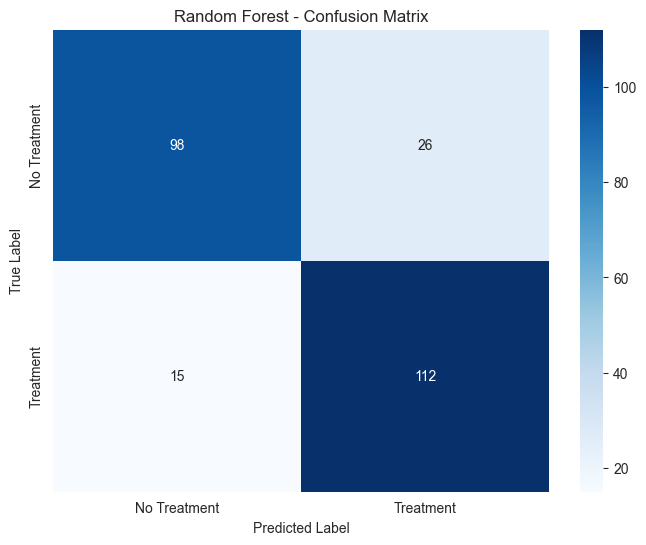


Confusion Matrix:
[[ 98  26]
 [ 15 112]]


In [8]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
fig = plot_confusion_matrix(cm, ['No Treatment', 'Treatment'], 'Random Forest - Confusion Matrix')
save_figure(fig, 'rf_confusion_matrix', output_dir='../outputs/figures')
plt.show()

print(f"\nConfusion Matrix:")
print(cm)

## Feature Importance

In [9]:
# Get feature importances
importances = best_rf.feature_importances_
feature_names = X.columns.tolist()

# Create DataFrame for feature importances
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

# Print top 5 features
print("\nTop 5 Most Important Features:")
for i, row in importance_df.head(5).iterrows():
    print(f"{row['feature']}: {row['importance']:.4f} ({row['importance']*100:.2f}%)")


Top 5 Most Important Features:
work_interfere: 0.2902 (29.02%)
Age: 0.0739 (7.39%)
family_history: 0.0720 (7.20%)
no_employees: 0.0431 (4.31%)
leave: 0.0416 (4.16%)


Saved figure to ../outputs/figures\rf_feature_importance.png


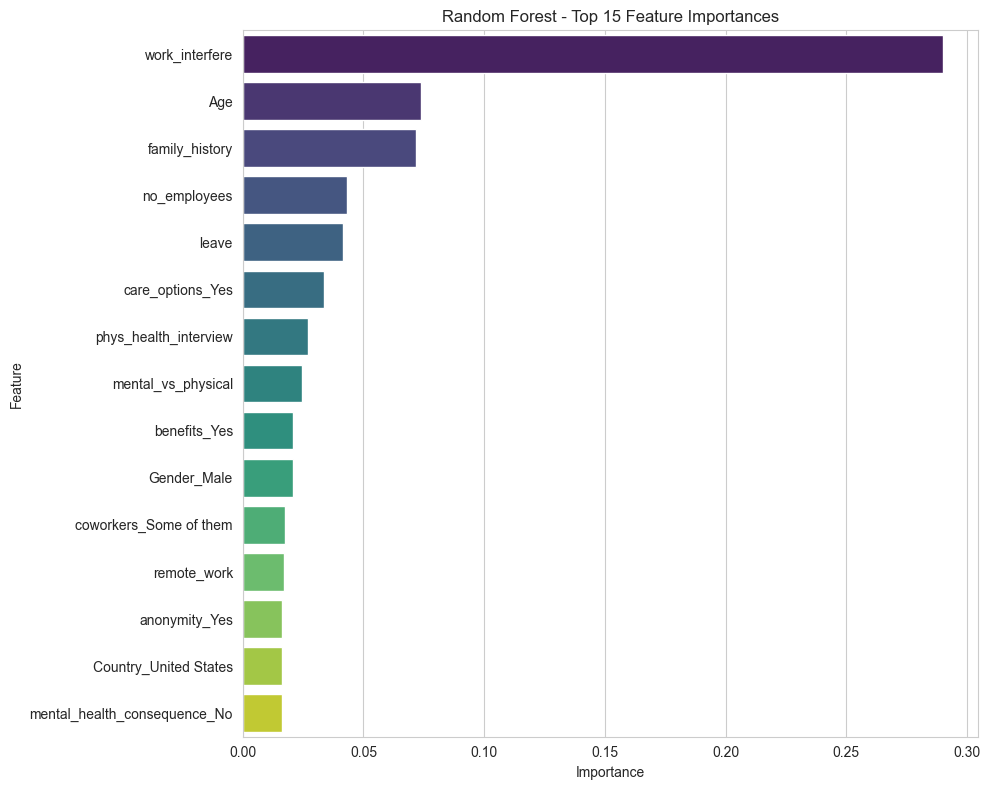

In [10]:
# Plot feature importance (top 15)
fig = plot_feature_importance(importances, feature_names, top_n=15, 
                              title='Random Forest - Top 15 Feature Importances')
save_figure(fig, 'rf_feature_importance', output_dir='../outputs/figures')
plt.show()

## Save Trained Model

In [11]:
# Ensure models directory exists
os.makedirs('../outputs/models', exist_ok=True)

# Save the best model
model_path = '../outputs/models/random_forest.pkl'
joblib.dump(best_rf, model_path)

print(f"Model saved to: {model_path}")

Model saved to: ../outputs/models/random_forest.pkl


## Interpretation

In [12]:
print("="*70)
print("RANDOM FOREST MODEL INTERPRETATION")
print("="*70)
print("\nThe Random Forest model found that the most important predictors of")
print("treatment-seeking are:")
print("\n1. Work Interfere - How much mental health issues interfere with work")
print("2. Family History - Whether the respondent has a family history of mental illness")
print("3. Age - The age of the respondent")
print("4. Benefits - Whether the employer provides mental health benefits")
print("5. Care Options - Whether the employer provides care options")
print("\nKey Insights:")
print("- Employees whose mental health issues interfere with their work are")
print("  significantly more likely to seek treatment.")
print("- Family history is a strong predictor, suggesting genetic or environmental")
print("  factors play a role in treatment-seeking behavior.")
print("- Workplace policies (benefits, care options) are important predictors,")
print("  indicating that company support systems influence treatment-seeking.")
print("\nThe model achieved an F1 score of {:.2f} (macro), indicating good")
print("predictive performance for identifying employees likely to seek treatment.".format(f1_macro))
print("="*70)

RANDOM FOREST MODEL INTERPRETATION

The Random Forest model found that the most important predictors of
treatment-seeking are:

1. Work Interfere - How much mental health issues interfere with work
2. Family History - Whether the respondent has a family history of mental illness
3. Age - The age of the respondent
4. Benefits - Whether the employer provides mental health benefits
5. Care Options - Whether the employer provides care options

Key Insights:
- Employees whose mental health issues interfere with their work are
  significantly more likely to seek treatment.
- Family history is a strong predictor, suggesting genetic or environmental
  factors play a role in treatment-seeking behavior.
- Workplace policies (benefits, care options) are important predictors,
  indicating that company support systems influence treatment-seeking.

The model achieved an F1 score of {:.2f} (macro), indicating good
predictive performance for identifying employees likely to seek treatment.
